# Steam Store Scraper

Automates a search on the Steam store with Selenium, filters the results to games under €5 with the price slider, and extracts the title, rating, price, original price, discount and link of each game into a DataFrame. It ends with a chart of how the discounts are distributed.

**Requirements:** Google Chrome and the packages in [`../requirements.txt`](../requirements.txt). Selenium 4.6+ downloads a matching ChromeDriver automatically.

## 1. Start the browser and open the Steam store

In [1]:
import pandas as pd
import time
from selenium import webdriver  # WebDriver automates the browser
from selenium.webdriver.common.by import By

# Selenium Manager (Selenium 4.6+) finds or downloads a matching ChromeDriver,
# so no local driver path is needed
options = webdriver.ChromeOptions()

# Create the browser instance
driver = webdriver.Chrome(options=options)

# URL of the page to automate
url = "https://store.steampowered.com/?l=spanish"
driver.get(url)  # Open the URL

## 2. Open the search results page

In [2]:
from selenium.webdriver.common.by import By
from selenium.webdriver.common.action_chains import ActionChains  # ActionChains handles complex interactions on the page
import time

# Find the search box on the Steam page by its ID
element = driver.find_element(By.ID, "store_nav_search_term")
from selenium.webdriver.common.keys import Keys  # Keys simulates keyboard keys
element.send_keys(Keys.ENTER)  # Press Enter in the search box

## 3. Set the price slider to under €5

In [3]:
# Select the price range slider, identified by the ID "price_range"
slider = driver.find_element(By.ID, "price_range")

# ActionChains instance for advanced browser actions
actions = ActionChains(driver)

# Set the slider value to 1 (under €5)
# The script changes the value of `slider` directly, without dragging it
driver.execute_script("arguments[0].value = 1;", slider)

# Fire an `input` event so the page detects the new value
driver.execute_script("arguments[0].dispatchEvent(new Event('input'));", slider)

# Fire a `change` event: the user finished changing the value, so dependent elements update
driver.execute_script("arguments[0].dispatchEvent(new Event('change'));", slider)

# Fire a `mouseup` event, as if the user released the slider
driver.execute_script("arguments[0].dispatchEvent(new MouseEvent('mouseup'));", slider)

## 4. Extract the data of each game into a DataFrame

In [4]:
# Find every search result row
elements = driver.find_elements(By.CLASS_NAME, "search_result_row")

# Empty lists to store the data of each game
nombres=[]             # Game titles
precio=[]              # Final price
descuento=[]           # Discount
valoraciones=[]        # User ratings
precio_original=[]     # Original price before the discount
links=[]               # Link to each game

# Loop over the search results
for item in elements:
    # Title
    nombre=item.find_element(By.XPATH, ".//span[@class = 'title']").text
    nombres.append(nombre)
    # User rating
    valoracion=item.find_element(By.XPATH, ".//span[contains(@class, 'search_review_summary')]").get_attribute("data-tooltip-html")
    valoraciones.append(valoracion)
    # Final price
    price=item.find_element(By.XPATH, ".//div[contains(@class, 'discount_final_price')]").text
    precio.append(price)

    # Discount, if any; otherwise "Sin descuento" (no discount)
    try:
        rebaja = item.find_element(By.XPATH, ".//div[contains(@class, 'discount_pct')]").text
    except:
        rebaja = "Sin descuento"
    descuento.append(rebaja)

    # Link to the game
    link = item.get_attribute("href")
    links.append(link)

    # Original price if there is one; otherwise use the final price
    try:
        original=item.find_element(By.XPATH, ".//div[contains(@class, 'discount_original_price')]").text
    except:
        original=price
    precio_original.append(original)

In [5]:
# Build a DataFrame to organize and view the extracted data
dfL = pd.DataFrame(zip(nombres, valoraciones, precio , precio_original, descuento, links), columns=['Nombre','Valoraciones','Precio', 'Precio original', 'Descuento', 'Link'])
dfL

,Nombre,Valoraciones,Precio,Precio original,Descuento,Link
0,Euro Truck Simulator 2,Extremadamente positivas<br>El 97 % de las 605...,"4,99€","19,99€",-75%,https://store.steampowered.com/app/227300/Euro...
1,Black Desert,"Mayormente positivas<br>El 75 % de las 56,769 ...","0,99€","9,99€",-90%,https://store.steampowered.com/app/582660/Blac...
2,Vampire Survivors,Extremadamente positivas<br>El 98 % de las 225...,"3,74€","4,99€",-25%,https://store.steampowered.com/app/1794680/Vam...
3,The Forest,Extremadamente positivas<br>El 95 % de las 475...,"3,35€","16,79€",-80%,https://store.steampowered.com/app/242760/The_...
4,Brotato,"Extremadamente positivas<br>El 96 % de las 78,...","2,99€","4,99€",-40%,https://store.steampowered.com/app/1942280/Bro...
5,Buckshot Roulette,"Extremadamente positivas<br>El 95 % de las 32,...","2,54€","2,99€",-15%,https://store.steampowered.com/app/2835570/Buc...
6,DiRT Rally 2.0,"Muy positivas<br>El 88 % de las 32,153 reseñas...","1,99€","19,99€",-90%,https://store.steampowered.com/app/690790/DiRT...
7,Wallpaper Engine,Extremadamente positivas<br>El 98 % de las 771...,"3,99€","3,99€",Sin descuento,https://store.steampowered.com/app/431960/Wall...
8,American Truck Simulator,Extremadamente positivas<br>El 97 % de las 133...,"4,99€","19,99€",-75%,https://store.steampowered.com/app/270880/Amer...
9,Battlefield™ 2042,"Variadas<br>El 47 % de las 215,760 reseñas de ...","4,79€","59,99€",-92%,https://store.steampowered.com/app/1517290/Bat...


In [ ]:
# Close the browser once the data is in the DataFrame
driver.quit()

## 5. Discount distribution of games under €5

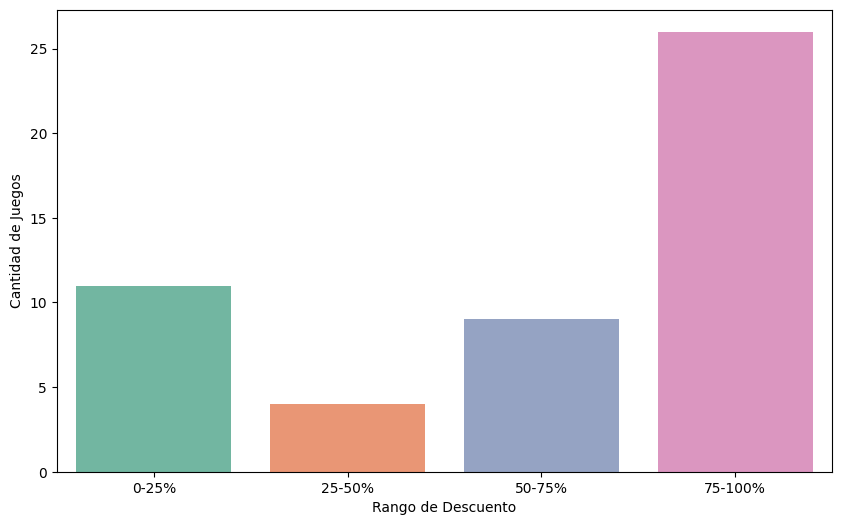

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

df=dfL.copy()

# Clean the 'Descuento' column: remove the '%' sign and set games without a discount to 0
df['Descuento'] = df['Descuento'].replace('Sin descuento', '0').str.replace('%', '').astype(float)

# Make the values positive
df['Descuento'] = df['Descuento'].abs()

# Discount ranges and their labels
ranges = [0, 25, 50, 75, 100]
labels = ['0-25%', '25-50%', '50-75%', '75-100%']

# Put each game in a discount range
df['Descuento Rango'] = pd.cut(df['Descuento'], bins=ranges, labels=labels, include_lowest=True)

# Frequency table
discount_counts = df['Descuento Rango'].value_counts().sort_index()
discount_counts_df = discount_counts.reset_index()
discount_counts_df.columns = ['Rango de Descuento', 'Cantidad de Juegos']

# Bar chart with Seaborn
plt.figure(figsize=(10, 6))
sns_barplot = sns.barplot(x=discount_counts_df['Rango de Descuento'], y=discount_counts_df['Cantidad de Juegos'], palette="Set2")
# Show the chart
plt.show()

## Results

The scraper collected 50 games under €5 from the first page of results. 47 of them were on sale, and the median discount among those was 80%. By discount range: 26 games in 75-100%, 9 in 50-75%, 4 in 25-50% and 11 in 0-25%.

Most of these games normally cost more: the median original price of the games on sale was €19.50. Steam's offers change all the time, so a new run will return different games.